PHASE 1: Data Ingestion & Engineering (ETL)

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Set visual style
sns.set_theme(style="whitegrid")

In [4]:
# Load a public weather/air quality sample dataset (e.g., daily weather or pollution metrics)
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/raw/dowjones.csv" # Or a weather dataset link
# Alternatively, if you have a local parquet file:
# df = pd.read_parquet('your_file.parquet')

In [5]:
# For demonstration, let's use a reliable weather-like or temporal dataset example:
url_weather = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/daily-min-temperatures.csv"
df = pd.read_csv(url_weather)

In [6]:
print("Data loaded successfully!")
df.head()

Data loaded successfully!


,Date,Temp
0,1981-01-01,20.7
1,1981-01-02,17.9
2,1981-01-03,18.8
3,1981-01-04,14.6
4,1981-01-05,15.8


HUMAN REVIEW & DATA CLEANING

In [7]:
# 1. Check data types and structure
print("--- Data Info ---")
df.info()

--- Data Info ---
<class 'pandas.DataFrame'>
RangeIndex: 3650 entries, 0 to 3649
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    3650 non-null   str    
 1   Temp    3650 non-null   float64
dtypes: float64(1), str(1)
memory usage: 92.8 KB


In [8]:
# 2. Check for missing (null) values
print("\n--- Missing Values ---")
print(df.isnull().sum())


--- Missing Values ---
Date    0
Temp    0
dtype: int64


In [11]:
# 3. Clean & Transform: Convert date column to actual datetime objects
df['Date'] = pd.to_datetime(df['Date'])

In [12]:
# Set Date as the index (crucial for time series!)
df.set_index('Date', inplace=True)

In [13]:
# Sort chronologically just in case
df.sort_index(inplace=True)

In [14]:
df.head()

,Temp
Date,
1981-01-01,20.7
1981-01-02,17.9
1981-01-03,18.8
1981-01-04,14.6
1981-01-05,15.8


In [15]:
print("--- Data Info ---")
df.info()

--- Data Info ---
<class 'pandas.DataFrame'>
DatetimeIndex: 3650 entries, 1981-01-01 to 1990-12-31
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Temp    3650 non-null   float64
dtypes: float64(1)
memory usage: 57.0 KB


PHASE 2: Exploratory Data Analysis & Statistics (Math & Stats Connection)

In [16]:
# Extract the numeric column (e.g., temperatures or pollutant levels)
metric_col = df.columns[0] # Gets the temperature/value column name

In [17]:
# Calculate basic statistics
mean_val = df[metric_col].mean()
median_val = df[metric_col].median()
std_val = df[metric_col].std()
var_val = df[metric_col].var()
skew_val = df[metric_col].skew()

In [18]:
print(f"--- Statistical Summary for {metric_col} ---")
print(f"Mean: {mean_val:.2f}")
print(f"Median: {median_val:.2f}")
print(f"Standard Deviation (Volatility): {std_val:.2f}")
print(f"Variance: {var_val:.2f}")
print(f"Skewness: {skew_val:.2f}")

--- Statistical Summary for Temp ---
Mean: 11.18
Median: 11.00
Standard Deviation (Volatility): 4.07
Variance: 16.58
Skewness: 0.17


The data shows is quite even.
The volatile is low, it means that the temperature are predictable and stable condition.
The data shows that the temperature are stable enough that extreme high or low temperature are balanced.

Phase 3: Moving Averages & Time Series

In [19]:
# Compute 7-day and 30-day rolling averages
df['7_Day_MA'] = df[metric_col].rolling(window=7).mean()
df['30_Day_MA'] = df[metric_col].rolling(window=30).mean()

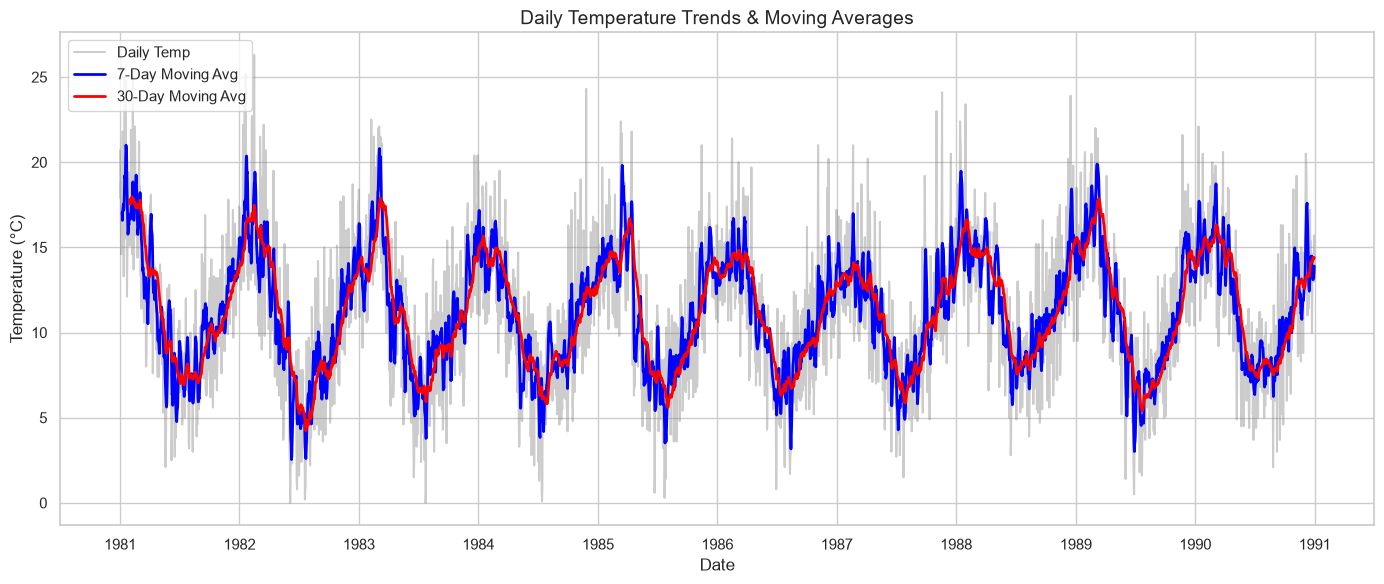

In [24]:
plt.figure(figsize=(14, 6))

# Plot lines with explicit labels
plt.plot(df.index, df[metric_col], label='Daily Temp', alpha=0.4, color='gray')
plt.plot(df.index, df['7_Day_MA'], label='7-Day Moving Avg', color='blue', linewidth=2)
plt.plot(df.index, df['30_Day_MA'], label='30-Day Moving Avg', color='red', linewidth=2)

# Formatting and rendering the legend correctly
plt.title('Daily Temperature Trends & Moving Averages', fontsize=14)
plt.xlabel('Date')
plt.ylabel('Temperature (°C)')
plt.legend(loc='upper left') # This forces the legend to appear with the labels
plt.tight_layout()
plt.show()

The wave plot shows consistent moving average against the temperature trends over the course of 10 years. This shows that the temperature did not have extreme temperature

Phase 4 : Automated Email Report

In [25]:
import smtplib
from email.mime.multipart import MIMEMultipart
from email.mime.text import MIMEText
from email.mime.image import MIMEImage
import matplotlib.pyplot as plt

In [33]:
# --- STEP 1: Generate and Save the Chart Locally ---
plt.figure(figsize=(10, 5))
plt.plot(df.index, df[metric_col], label='Daily Temp', alpha=0.4, color='gray')
plt.plot(df.index, df['7_Day_MA'], label='7-Day Moving Avg', color='blue', linewidth=2)
plt.plot(df.index, df['30_Day_MA'], label='30-Day Moving Avg', color='red', linewidth=2)
plt.title('Automated Daily Temperature & Moving Average Report')
plt.xlabel('Date')
plt.ylabel('Temperature (°C)')
plt.legend(loc='upper left')
plt.tight_layout()

# Save the plot as an image file
chart_filename = 'weather_report_chart.png'
plt.savefig(chart_filename, bbox_inches='tight')
plt.close() # Close the plot so it doesn't overlap in Jupyter
print("Chart generated and saved successfully!")

Chart generated and saved successfully!


In [34]:
# --- STEP 2: Configure Email Credentials ---
# Note: If using Gmail, you must generate an "App Password" from your Google Account security settings 
# rather than using your actual personal account password.
sender_email = "nuruldalia01@gmail.com"
receiver_email = "nuruldalia01@gmail.com"  # You can send it to yourself for testing
app_password = "fkdh mzwo mkdr ydyh"

In [35]:
# --- STEP 3: Compose the Email Message ---
msg = MIMEMultipart()
msg['Subject'] = 'Automated Data Science Daily Weather Report'
msg['From'] = sender_email
msg['To'] = receiver_email

# Embed your statistical findings directly into the email body text
email_body = f"""
Hello! Here is your automated daily data science and statistics report.

--- Statistical Summary ---
- Metric Analyzed: {metric_col}
- Mean (Central Tendency): {mean_val:.2f}
- Median: {median_val:.2f}
- Standard Deviation (Volatility): {std_val:.2f}
- Skewness: {skew_val:.2f}

The latest time-series trend chart has been attached to this email. Have a great day!
"""
msg.attach(MIMEText(email_body, 'plain'))

In [36]:
# --- STEP 4: Attach the Saved Chart Image ---
with open(chart_filename, 'rb') as f:
    img_data = f.read()

image_attachment = MIMEImage(img_data, name=chart_filename)
msg.attach(image_attachment)

In [37]:
# --- STEP 5: Connect to SMTP Server and Send ---
try:
    # Connecting to Gmail's SMTP server securely via TLS port 587
    server = smtplib.SMTP('smtp.gmail.com', 587)
    server.starttls() 
    server.login(sender_email, app_password)
    server.sendmail(sender_email, receiver_email, msg.as_string())
    server.quit()
    print("Email report sent successfully!")
except Exception as e:
    print(f"An error occurred while sending the email: {e}")

Email report sent successfully!
